# Modelo recomendador de peliculas
movie lens

In [3]:
# Importando librerias

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold


In [4]:
calificaciones = pd.read_csv("ml-latest-small/ratings.csv")
peliculas = pd.read_csv("ml-latest-small/movies.csv")
titulo = peliculas.set_index("movieId")["title"]   # para traducir movieId → título

In [5]:
# Imprimiendo el dataframe de peliculas
peliculas.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [6]:
calificaciones.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [7]:
# Haciendo validaciones de los datos
n_usuarios = calificaciones["userId"].nunique()
n_peliculas = calificaciones["movieId"].nunique()
print("Calificaciones:", len(calificaciones))
print("Usuarios:", n_usuarios)
print("Películas con al menos una calificación:", n_peliculas)
print(f"Celdas llenas de la tabla usuario × película: {len(calificaciones) / (n_usuarios * n_peliculas):.1%}")

Calificaciones: 100836
Usuarios: 610
Películas con al menos una calificación: 9724
Celdas llenas de la tabla usuario × película: 1.7%


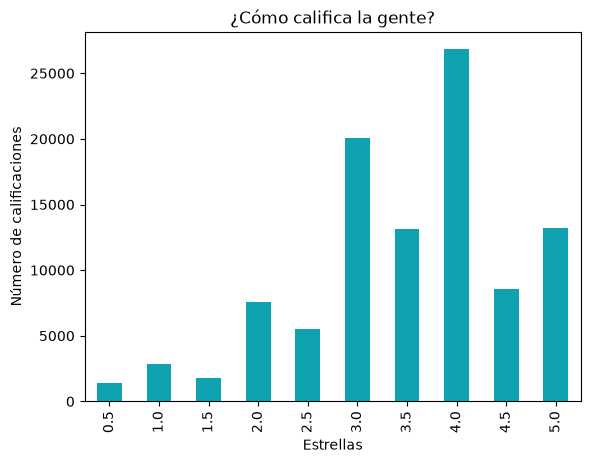

In [8]:
calificaciones["rating"].value_counts().sort_index().plot(kind="bar", color="#0FA3B1")
plt.title("¿Cómo califica la gente?")
plt.xlabel("Estrellas")
plt.ylabel("Número de calificaciones")
plt.show()


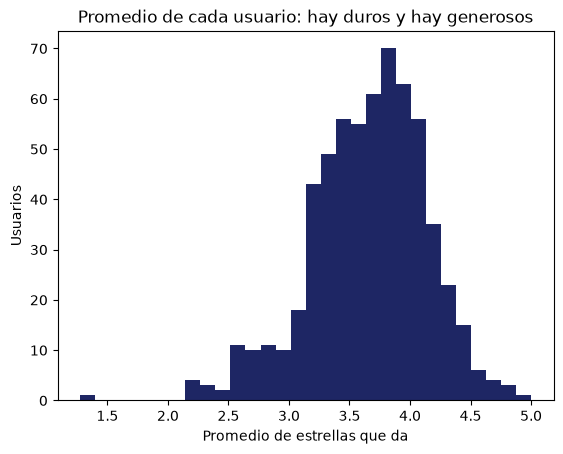

userId
442    1.275000
139    2.144330
508    2.145833
153    2.217877
567    2.245455
         ...   
30     4.735294
25     4.807692
515    4.846154
251    4.869565
53     5.000000
Name: rating, Length: 610, dtype: float64

In [9]:
# distribucion de prmedios de calificacion del usuario
promedio_por_usuario = calificaciones.groupby("userId")["rating"].mean()
promedio_por_usuario.plot(kind="hist", bins=30, color="#1E2664")
plt.title("Promedio de cada usuario: hay duros y hay generosos")
plt.xlabel("Promedio de estrellas que da")
plt.ylabel("Usuarios")
plt.show()
promedio_por_usuario.sort_values()

In [10]:
conteo = calificaciones["movieId"].value_counts()   # calificaciones por película
print("Películas con UNA sola calificación:", (conteo == 1).sum())
print("Mediana de calificaciones por película:", conteo.median())
print("Mediana de calificaciones por película:", conteo.mean())

Películas con UNA sola calificación: 3446
Mediana de calificaciones por película: 3.0
Mediana de calificaciones por película: 10.369806663924312
